# 08 · Pilot AnimeInbet distillation using cached GMA motion

Test whether learning from AnimeInbet predictions improves the unmasked epoch-13 U-Net. Train two copies on the same 512 training examples: one learns from true middle drawings alone; the other also learns from cached AnimeInbet predictions. Compare them on the same 96 validation examples.

**Setup:** Kaggle with a GPU, Stage 1 data, the epoch-13 checkpoint, and the complete previous cache folder in `OLD_OUT`. The pilot runs three additional epochs. Cached training needs no new GMA or AnimeInbet inference.

**Saves:** Both trained models, the original epoch-13 model, comparison scores, previews, and a results ZIP. Motion and teacher caches remain separate.

## Set inputs and cache paths

Set `OLD_OUT` to the complete previous output, including `gma_coarse_flow/` and `teacher/`. A results-only ZIP is insufficient. Both new training runs start from epoch 13, with seed 42 and the same 512/96 example split.

In [ ]:
from pathlib import Path

DATA = Path(
    "/kaggle/input/datasets/epicfaez/interframes-stage1-output/interframes_tf_stage1"
)
EPOCH13_DIR = Path(
    "/kaggle/input/datasets/epicfaez/interframes-stage2-ink15/interframes_tf_stage2_ink15"
)

# Optional local copy of the ORIGINAL ML240, including JSON graphs. Use a folder
# containing 'ml144_norm_100_44_split', or a readable ml240data.zip file.
RAW_DATA_ROOT = None
RAW_ZIP = None
TEACHER_CKPT = None  # Optional path to already downloaded epoch_20.pt
GMA_CKPT = None  # Optional path to the pretrained AnimeRun GMA checkpoint

OLD_OUT = Path(
    "/kaggle/working/interframes_distillation08"
)  # CHANGE if old cache is attached under /kaggle/input
OUT = Path("/kaggle/working/interframes_distillation08_inkfix")
TEMP = Path("/kaggle/temp/interframes_distillation08_inkfix")
TRAIN_LIMIT, VAL_LIMIT = 512, 96
SEED, EPOCHS, BATCH_SIZE = 42, 3, 4
GMA_ITERS = 12  # Match the configuration used in notebook 07
FLOW_MODE = "coarse"  # 'coarse' = GMA low-grid -> Stage-1 forward splat; no full-flow extrapolation
LEARNING_RATE = 2e-5  # New identical Adam optimizer for both branches
KD_MAX_WEIGHT = 0.20  # Ramped in over the first two epochs; only the distilled branch
TEACHER_LINE_WIDTH = 2  # Notebook 07's original-resolution graph rendering thickness
PREVIEW_COUNT = 5
INFERENCE_A = None  # After training: upload two user PNG paths, or leave as None
INFERENCE_B = None

assert FLOW_MODE == "coarse", (
    "This pilot implements the exact 07 GMA coarse feature convention."
)
for folder in (OUT, TEMP):
    folder.mkdir(parents=True, exist_ok=True)
print("Output:", OUT)

Output: /kaggle/working/interframes_distillation08_inkfix


## Check inputs and select examples

Check the Stage 1 identifier and epoch-13 training state, then choose repeatable training and validation examples. Validate and link the old caches into the new output folder. The model-weight hash is checked before training.

In [ ]:
import collections, contextlib, csv, gc, hashlib, importlib.util, json, math
import os, random, re, shutil, subprocess, sys, time, zipfile
from functools import lru_cache

import numpy as np
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tqdm.auto import tqdm
from IPython.display import display, FileLink

# Kaggle normally supplies SciPy, PIL, NumPy, PyTorch, OpenCV, and TensorFlow.
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "-q",
        "install",
        "huggingface_hub",
        "gdown",
        "easydict",
        "scikit-network",
        "pyyaml",
    ],
    check=True,
)

assert (DATA / "stage1_complete.json").is_file(), f"Attach Stage 1: {DATA}"
assert (DATA / "modules/data.py").is_file(), "Stage 1 modules/data.py missing"
assert (EPOCH13_DIR / "training_state.json").is_file(), (
    f"Attach unmasked ink15: {EPOCH13_DIR}"
)
sys.path.insert(0, str(DATA / "modules"))
import data as raster


def read_json(p):
    return json.loads(Path(p).read_text())


def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".part")
    tmp.write_text(json.dumps(obj, indent=2, sort_keys=True, default=str))
    tmp.replace(path)


def sha256(path, block=4 << 20):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()


stage = read_json(DATA / "stage1_complete.json")
state13 = read_json(EPOCH13_DIR / "training_state.json")
base_cfg = state13["run_config"]
assert state13.get("experiment") == "epoch10_ink30_to_ink15", (
    "Not the unmasked ink-15 experiment"
)
assert base_cfg.get("positive_weight") == 15, "Requires the unmasked ink-15 model"
assert base_cfg.get("data_fingerprint") == stage["fingerprint"], (
    "Stage 1 fingerprint differs"
)
assert base_cfg.get("feature_version") == "tf-ink8-lowflow16-v2", (
    "Unexpected feature version"
)
assert not state13.get("partial") or state13.get("best_epoch") == 13, (
    "Partial model with no verified epoch-13 best"
)
if state13["completed_epochs"] == 13 and not state13.get("partial"):
    BASE_PATH = EPOCH13_DIR / "last.keras"
elif state13.get("best_epoch") == 13:
    BASE_PATH = EPOCH13_DIR / "best.keras"
else:
    raise ValueError(
        "Attach an unmasked checkpoint with actual epoch-13 weights, not just epoch-13 history."
    )
assert BASE_PATH.is_file(), BASE_PATH
base_entry = next(h for h in state13["history"] if h["epoch"] == 13)
BASE_DIGEST = base_entry["weights_digest"]
SIZE = int(read_json(DATA / "config.json")["size"])
assert SIZE == 256 and len(BASE_DIGEST) == 64, "Check Stage 1 size and epoch-13 digest"

all_rows = raster.read_records(DATA)
tr_rows = [r for r in all_rows if r["split"] == "train"]
va_rows = [r for r in all_rows if r["split"] == "val"]
assert tr_rows and va_rows, "Training / validation manifest missing"
assert {r["sequence"] for r in tr_rows}.isdisjoint({r["sequence"] for r in va_rows})


def spread_sample(rows, limit, seed):
    # Round-robin over (sequence,gap) groups to sample many actions and motion scales.
    groups = collections.defaultdict(list)
    for row in rows:
        groups[(row["sequence"], row["gap"])].append(row)
    rng = random.Random(seed)
    keys = sorted(groups)
    for k in keys:
        rng.shuffle(groups[k])
    rng.shuffle(keys)
    if limit is None:
        limit = len(rows)
    chosen = []
    for turn in range(max(map(len, groups.values()))):
        for k in keys:
            if turn < len(groups[k]):
                chosen.append(groups[k][turn])
                if len(chosen) >= limit:
                    return chosen
    return chosen


train_rows = spread_sample(tr_rows, TRAIN_LIMIT, SEED)
val_rows = spread_sample(va_rows, VAL_LIMIT, SEED + 1)
assert train_rows and val_rows
assert not ({r["id"] for r in train_rows} & {r["id"] for r in val_rows})
rows = train_rows + val_rows
row_by_id = {r["id"]: r for r in rows}

print(
    "Parent:",
    BASE_PATH.name,
    "| verified state epoch 13 | sha256(weights)",
    BASE_DIGEST[:16],
)
print("Stage 1 fingerprint:", stage["fingerprint"][:16])
print(
    "Sampled:",
    len(train_rows),
    "train +",
    len(val_rows),
    "val",
    "| unique sequences:",
    len({r["sequence"] for r in train_rows}),
    "/",
    len({r["sequence"] for r in val_rows}),
)
print("Gaps:", dict(collections.Counter(r["gap"] for r in rows)))

Parent: last.keras | verified state epoch 13 | sha256(weights) 980fdd951fafcf04
Stage 1 fingerprint: 0a6873b0e80d50f4
Sampled: 512 train + 96 val | unique sequences: 100 / 40
Gaps: {4: 198, 2: 201, 1: 209}


In [ ]:
# Verify the previous 608-sample caches, then link them read-only into the NEW run.
# Reuses: GMA low flows, extracted ML240 graph+endpoint pairs, teacher middle PNGs.
# Only newly trained checkpoints/metrics are written to OUT.
assert OLD_OUT.resolve() != OUT.resolve(), "OLD_OUT and OUT must be different"
assert len(train_rows) == 512 and len(val_rows) == 96, (
    "Pilot cache reuse requires 512 train + 96 val"
)
old_flow = OLD_OUT / "gma_coarse_flow"
old_teacher = OLD_OUT / "teacher"
for marker in (old_flow / "provenance.json", old_teacher / "provenance.json"):
    assert marker.is_file(), (
        f"Missing previous cache: {marker}. "
        "Attach the FULL previous output (not just the results ZIP) "
        "and set OLD_OUT in configuration."
    )
old_flow_prov = read_json(old_flow / "provenance.json")
old_teacher_prov = read_json(old_teacher / "provenance.json")
assert old_flow_prov["stage_fingerprint"] == stage["fingerprint"], (
    "GMA cache dataset mismatch"
)
assert old_teacher_prov["stage_fingerprint"] == stage["fingerprint"], (
    "Teacher cache dataset mismatch"
)
assert old_flow_prov["size"] == SIZE and old_flow_prov["iterations"] == GMA_ITERS
assert old_flow_prov["mode"] == FLOW_MODE
assert old_teacher_prov["line_width"] == TEACHER_LINE_WIDTH
assert old_teacher_prov["repo_revision"] == "cc5554feb9d8943f1fc5f0b90854ef15cd3e8335"
assert old_teacher_prov["preparation"] == "original_ml240_graphs_to_256px_v1"
for r in tqdm(rows, desc="Validate old cached inputs"):
    flow = old_flow / r["split"] / (r["id"] + ".npy")
    teacher = old_teacher / "predictions" / r["split"] / (r["id"] + ".png")
    assert flow.is_file() and teacher.is_file(), (
        f"Missing cached flow/teacher: {r['id']}"
    )
    f = np.load(flow, mmap_mode="r", allow_pickle=False)
    assert f.shape == (2, SIZE // 8, SIZE // 8, 2) and np.isfinite(f).all(), flow
    with Image.open(teacher) as im:
        assert im.size == (SIZE, SIZE) and im.getextrema()[0] < 255, teacher
    partition = "train" if r["split"] == "train" else "test"
    for side in (0, 1):
        num = int(r["middle_number"]) + (-int(r["gap"]) if side == 0 else int(r["gap"]))
        for kind, ext in (("frames", ".png"), ("labels", ".json")):
            original = (
                old_teacher
                / "original_endpoints"
                / kind
                / partition
                / r["sequence"]
                / f"{num}{ext}"
            )
            paired = (
                old_teacher
                / "paired_inputs"
                / "pairs"
                / kind
                / r["id"]
                / f"{side}{ext}"
            )
            assert original.is_file() and paired.is_file(), (
                f"Missing cached graph/PNG: {original} or {paired}"
            )
for name in ("gma_coarse_flow", "teacher"):
    source = (OLD_OUT / name).resolve()
    target = OUT / name
    if target.is_symlink():
        assert target.resolve() == source, f"Wrong existing symlink: {target}"
    else:
        assert not target.exists(), f"{target} already exists; choose a fresh OUT"
        target.symlink_to(source, target_is_directory=True)
print(
    "Reused", len(rows), "previous flow+teacher PNGs + ML240 graph pairs from", OLD_OUT
)
print(
    "Old caches remain unchanged; NEW model and optimizer states start from epoch 13."
)

Validate old cached inputs:   0%|          | 0/608 [00:00<?, ?it/s]

Reused 608 previous flow+teacher PNGs + ML240 graph pairs from /kaggle/working/interframes_distillation08
Old caches remain unchanged; NEW model and optimizer states start from epoch 13.


## Reuse cached GMA motion

Read the 608 cached motion files after checking their dataset and settings. The worker below is available for optional inference on new PNGs, which may need to download GMA.

In [ ]:
# No GMA repository download / checkpoint load needed for cached training.
REPO_GMA = TEMP / "GMA"
FLOW_DIR = OUT / "gma_coarse_flow"  # verified symlink to OLD_OUT
flow_marker = FLOW_DIR / "provenance.json"
flow_signature = read_json(flow_marker)
assert flow_signature["stage_fingerprint"] == stage["fingerprint"]
assert flow_signature["size"] == SIZE and flow_signature["iterations"] == GMA_ITERS
assert flow_signature["mode"] == FLOW_MODE
GMA_SHA = flow_signature["checkpoint_sha256"]
GMA_REV = flow_signature["repo_revision"]
assert len(GMA_SHA) == 64
jobs_file = OUT / "gma_jobs.json"
atomic_json(
    jobs_file, [dict(id=r["id"], a=r["a"], b=r["b"], split=r["split"]) for r in rows]
)
print("Using prior GMA revision:", GMA_REV[:10], "| cached model SHA:", GMA_SHA[:12])

Using prior GMA revision: 2f1fd29468 | cached model SHA: 4a9faacbec5d


In [ ]:
GMA_WORKER = r"""
import argparse, json, sys
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

repo, checkpoint, root, out, jobs_path, steps = sys.argv[1:]
sys.path.insert(0, str(Path(repo) / 'core'))
from network import RAFTGMA

args = argparse.Namespace(small=False, mixed_precision=False, alternate_corr=False,
                          dropout=0.0, num_heads=1, position_only=False,
                          position_and_content=False)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = RAFTGMA(args)
weights = torch.load(checkpoint, map_location='cpu', weights_only=True)
model.load_state_dict({k.removeprefix('module.'): v for k, v in weights.items()}, strict=True)
model.to(device).eval()

def frame(p):
    with Image.open(Path(root) / p) as im:
        arr = np.asarray(im.convert('RGB'))
    return torch.from_numpy(arr.copy()).permute(2, 0, 1).float()

jobs = json.loads(Path(jobs_path).read_text())
with torch.inference_mode():
    for r in tqdm(jobs, desc='Cache GMA coarse flows'):
        dest = Path(out) / r['split'] / (r['id'] + '.npy')
        dest.parent.mkdir(parents=True, exist_ok=True)
        if dest.exists():
            existing = np.load(dest, mmap_mode='r')
            if existing.shape == (2, 32, 32, 2) and existing.dtype == np.float16 and np.isfinite(existing).all():
                continue
            raise RuntimeError(f'Corrupt cached flow: {dest}')
        pair = torch.stack([frame(r['a']), frame(r['b'])]).to(device)
        h, w = pair.shape[-2:]
        assert h == w == 256, (h, w)
        low, _ = model(pair, pair.flip(0), iters=int(steps), test_mode=True)
        assert tuple(low.shape) == (2, 2, 32, 32) and torch.isfinite(low).all()
        result = low.permute(0, 2, 3, 1).cpu().numpy().astype(np.float16)
        tmp = dest.with_suffix('.part.npy')
        np.save(tmp, result)
        tmp.replace(dest)
"""
WORKER_PATH = OUT / "gma_flow_worker08.py"
WORKER_PATH.write_text(GMA_WORKER)  # For optional two-PNG inference only
missing = [
    r["id"] for r in rows if not (FLOW_DIR / r["split"] / (r["id"] + ".npy")).is_file()
]
assert not missing, f"GMA cache incomplete: {missing[:5]}"
print(f"GMA cache reused: {len(rows)} flows; skipped GMA model and GPU computation.")

GMA cache reused: 608 flows; skipped GMA model and GPU computation.


## Reuse endpoint drawings and line graphs

Use the original ML240 endpoints and AnimeInbet input graphs from the verified previous cache. No new extraction or graph conversion runs here.

In [ ]:
# Teacher model does not load. Metadata comes from the previous cache.
ANIME_REV = "cc5554feb9d8943f1fc5f0b90854ef15cd3e8335"
TEACHER_DIR = OUT / "teacher"
ORIGINAL_CACHE = TEACHER_DIR / "original_endpoints"
PAIR_ROOT = TEACHER_DIR / "paired_inputs"
TEACHER_PNG = TEACHER_DIR / "predictions"
teacher_marker = TEACHER_DIR / "provenance.json"
teacher_signature = read_json(teacher_marker)
assert teacher_signature["stage_fingerprint"] == stage["fingerprint"]
assert teacher_signature["repo_revision"] == ANIME_REV
assert teacher_signature["line_width"] == TEACHER_LINE_WIDTH
assert teacher_signature["preparation"] == "original_ml240_graphs_to_256px_v1"
TEACHER_SHA = teacher_signature["checkpoint_sha256"]
assert len(TEACHER_SHA) == 64
print("Using cached AnimeInbet midpoint PNGs; teacher SHA:", TEACHER_SHA[:12])

Using cached AnimeInbet midpoint PNGs; teacher SHA: fe7896878df4


In [ ]:
# These original ML240 frames/graphs were extracted in the PREVIOUS run.
def frame_key(r, side):
    n = int(r["middle_number"]) + (-int(r["gap"]) if side == 0 else int(r["gap"]))
    return ("train" if r["split"] == "train" else "test", r["sequence"], n)


def source_cache_path(kind, key):
    partition, seq, num = key
    extension = ".png" if kind == "frames" else ".json"
    return ORIGINAL_CACHE / kind / partition / seq / (str(num) + extension)


assert PAIR_ROOT.is_dir() and ORIGINAL_CACHE.is_dir()
print("Original endpoint PNGs + graph JSONs reused; no ZIP extraction.")

Original endpoint PNGs + graph JSONs reused; no ZIP extraction.


## Check cached AnimeInbet predictions

Check that each example has a saved middle-frame PNG. AnimeInbet acts as the teacher: its saved predictions guide training, but its model is not loaded here.

In [ ]:
def teacher_png_path(r):
    return TEACHER_PNG / r["split"] / (r["id"] + ".png")


for r in rows:
    dest = teacher_png_path(r)
    assert dest.is_file(), f"Missing cached AnimeInbet PNG: {dest}"
print(f"AnimeInbet cache reused: {len(rows)} middle PNGs; no GPU teacher inference.")

AnimeInbet cache reused: 608 middle PNGs; no GPU teacher inference.


## Measure teacher quality

Compare each teacher prediction with the true middle. Use line F1 and excess ink to assign a weight from 0 to 1. Poor predictions receive less influence; the loss also excludes teacher ink more than three pixels from a true stroke.

Audit teacher against correct middle ink:   0%|          | 0/608 [00:00<?, ?it/s]

       line_f1  chamfer_px  ink_ratio   trust
split                                        
train   0.8214      2.2636     1.4471  0.5963
val     0.8469      1.1610     1.6257  0.5578
Trusted teacher examples (q > 0.01): 597 / 608


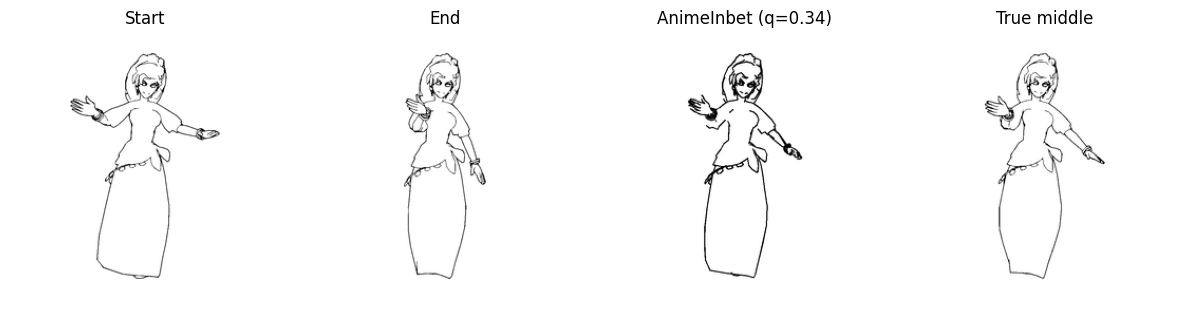

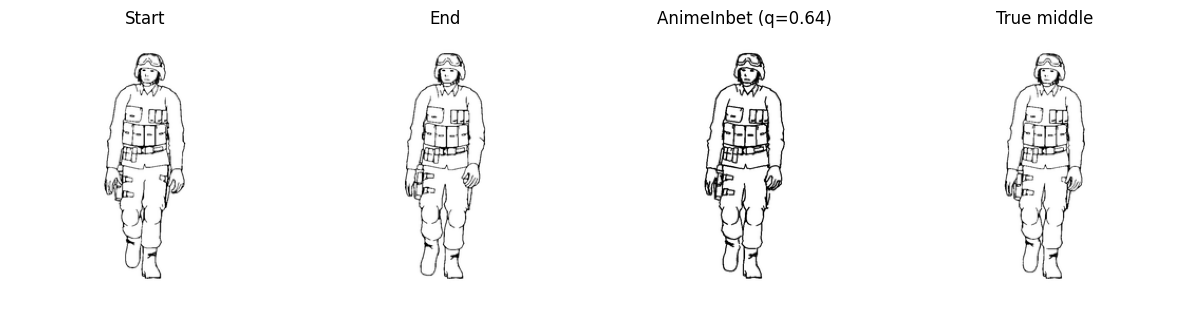

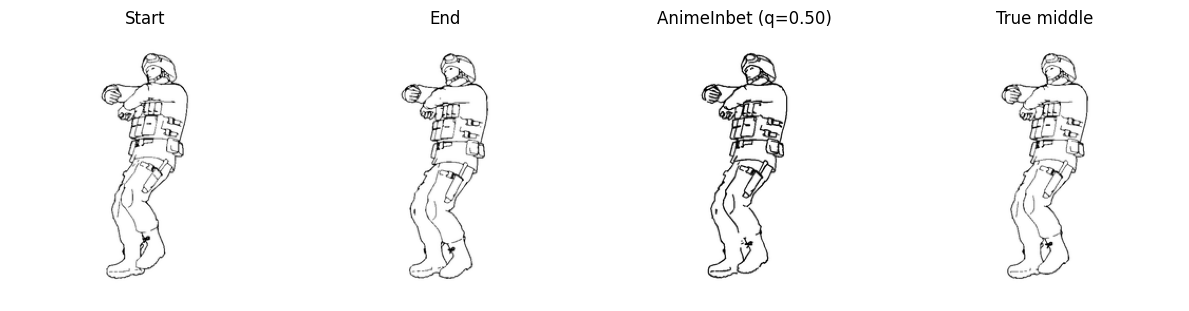

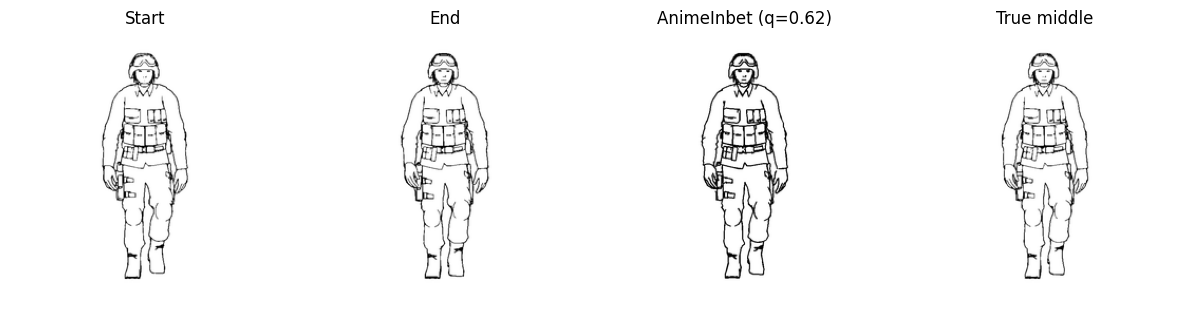

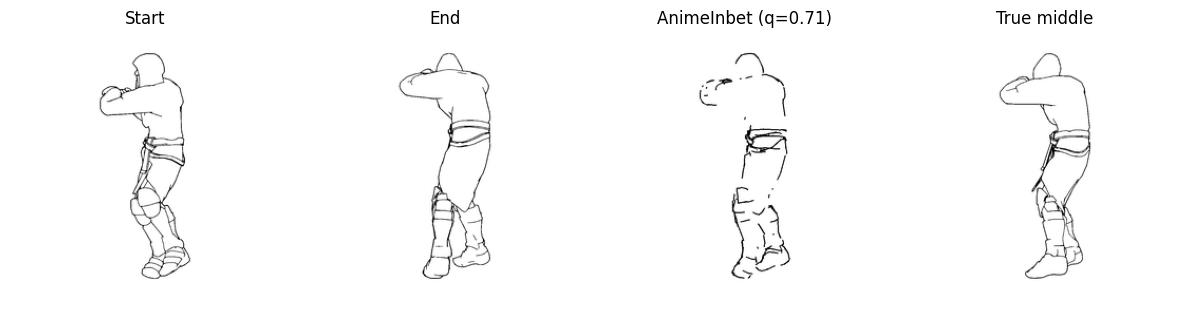

In [ ]:
import pandas as pd


def teacher_trust(pred, truth):
    s = raster.line_scores(pred, truth, threshold=0.5, tolerance=2)
    ratio = (float((pred >= 0.5).sum()) + 1) / (float((truth >= 0.5).sum()) + 1)
    # Soft gate: F1 < 0.25 gets no weight; F1 >= 0.60 gets full F1 weight.
    # Penalize strong ink over/under-production: ratio 0.5-2 can still have weight.
    f1_gate = float(np.clip((s["line_f1"] - 0.25) / 0.35, 0, 1))
    ratio_gate = float(np.clip(1 - abs(np.log(ratio)) / np.log(3), 0, 1))
    return s, ratio, f1_gate * ratio_gate


quality_records = []
for r in tqdm(rows, desc="Audit teacher against correct middle ink"):
    t = raster.read_ink(teacher_png_path(r))
    gt = raster.read_ink(DATA / r["target"])
    score, ratio, trust = teacher_trust(t, gt)
    quality_records.append(
        dict(
            id=r["id"],
            split=r["split"],
            sequence=r["sequence"],
            gap=r["gap"],
            trust=trust,
            ink_ratio=ratio,
            **score,
        )
    )
quality = pd.DataFrame(quality_records)
quality.to_csv(OUT / "teacher_quality.csv", index=False)
TRUST = dict(zip(quality["id"], quality["trust"]))
print(
    quality.groupby("split")[["line_f1", "chamfer_px", "ink_ratio", "trust"]]
    .mean()
    .round(4)
)
print(
    "Trusted teacher examples (q > 0.01):",
    int((quality.trust > 0.01).sum()),
    "/",
    len(quality),
)
assert (quality[quality.split == "train"].trust > 0.01).sum() >= max(
    5, len(train_rows) // 20
), (
    "Too few reliable AnimeInbet predictions. Inspect the cached teacher PNG and paired original graphs."
)

import matplotlib.pyplot as plt

for r in val_rows[: min(PREVIEW_COUNT, len(val_rows))]:
    a = raster.read_ink(DATA / r["a"])
    b = raster.read_ink(DATA / r["b"])
    gt = raster.read_ink(DATA / r["target"])
    teach = raster.read_ink(teacher_png_path(r))
    fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
    for ax, v, title in zip(
        axes,
        [a, b, teach, gt],
        ["Start", "End", f"AnimeInbet (q={TRUST[r['id']]:.2f})", "True middle"],
    ):
        ax.imshow(v, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    fig.savefig(OUT / f"teacher_preview_{r['id']}.png", dpi=120)
    plt.show()
    plt.close(fig)

## Build identical inputs for both runs

Each U-Net receives eight channels: two endpoint drawings, two motion-shifted drawings, two distance-to-line maps, and two coverage maps. True middle drawings, teacher predictions, and quality weights are used only to calculate training loss.

In [ ]:
def low_flow(r):
    dest = FLOW_DIR / r["split"] / (r["id"] + ".npy")
    low = np.load(dest, allow_pickle=False)
    assert low.shape == (2, SIZE // 8, SIZE // 8, 2) and np.isfinite(low).all()
    return low


@lru_cache(maxsize=128)
def load_ink(relative):
    return raster.read_ink(DATA / relative)


def make_example(r):
    # NO teacher, NO graph, NO target image enters this feature builder.
    a, b = load_ink(r["a"]), load_ink(r["b"])
    x = raster.features_from_low(a, b, low_flow(r))
    y = load_ink(r["target"])[..., None].copy()
    t = raster.read_ink(teacher_png_path(r))[..., None]
    gt_binary = y[..., 0] >= 0.5
    dt_gt = distance_transform_edt(~gt_binary).astype(np.float32)[..., None]
    trust = np.float32(TRUST[r["id"]])
    assert x.shape == (SIZE, SIZE, 8) and y.shape == t.shape == dt_gt.shape == (
        SIZE,
        SIZE,
        1,
    )
    assert np.isfinite(x).all() and np.isfinite(y).all() and np.isfinite(t).all()
    return (
        x.astype(np.float32),
        y.astype(np.float32),
        t.astype(np.float32),
        dt_gt,
        trust,
    )


example = make_example(train_rows[0])
assert example[0].shape[-1] == 8 and example[1].shape[-1] == 1
print(
    "X, GT, teacher, GT-distance, trust:",
    example[0].shape,
    example[1].shape,
    example[2].shape,
    example[3].shape,
    example[4],
)
print(
    "Channels:",
    [
        "start_ink",
        "end_ink",
        "start_warp",
        "end_warp",
        "start_distance",
        "end_distance",
        "start_coverage",
        "end_coverage",
    ],
)

X, GT, teacher, GT-distance, trust: (256, 256, 8) (256, 256, 1) (256, 256, 1) (256, 256, 1) 0.79661715
Channels: ['start_ink', 'end_ink', 'start_warp', 'end_warp', 'start_distance', 'end_distance', 'start_coverage', 'end_coverage']


## Define the training losses

**Both runs:** use ink weight 8, and penalize incorrect pixels, missing strokes, misplaced lines, broken contours, and too much or too little ink.

**Teacher-assisted run:** also compare smoothed student and teacher drawings near true strokes. Weight this term by teacher quality and increase its strength over the first two epochs. The ground-truth loss remains active in both runs.

In [ ]:
# Import TF only after both PyTorch preparation phases have released GPU allocations.
import tensorflow as tf
from tensorflow import keras
import learning

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
try:
    tf.config.experimental.enable_tensor_float_32_execution(False)
except Exception:
    pass
keras.utils.set_random_seed(SEED)
assert learning.FEATURE_VERSION == base_cfg["feature_version"]


# Actual epoch-13 .keras weight verification from notebook 07.
def model_digest(model):
    h = hashlib.sha256()
    for v in model.weights:
        a = v.numpy()
        for part in (str(a.shape).encode(), str(a.dtype).encode(), a.tobytes()):
            h.update(part)
    return h.hexdigest()


net0 = keras.models.load_model(BASE_PATH, compile=False)
assert net0.name == "interframes_unet"
assert tuple(net0.input_shape[1:]) == (SIZE, SIZE, 8)
assert tuple(net0.output_shape[1:]) == (SIZE, SIZE, 1)
assert model_digest(net0) == BASE_DIGEST, (
    "Actual epoch-13 model weights do not match history digest"
)
print(
    "EXACT epoch-13 weights verified. TF:",
    tf.__version__,
    "| Params:",
    net0.count_params(),
)
del net0
gc.collect()
keras.backend.clear_session()

EXACT epoch-13 weights verified. TF: 2.21.0 | Params: 1098745


In [ ]:
GT_LOSS = learning.InkLoss(positive_weight=8.0)


def soft_dice(a, b):
    overlap = 2.0 * tf.reduce_sum(a * b, axis=[1, 2, 3]) + 1.0
    total = tf.reduce_sum(a + b, axis=[1, 2, 3]) + 1.0
    return 1.0 - overlap / total


def loss_terms(gt, logits, teacher, dist_gt, trust, kd_scale):
    gt = tf.cast(gt, tf.float32)
    z = tf.cast(logits, tf.float32)
    t = tf.stop_gradient(tf.cast(teacher, tf.float32))
    d = tf.stop_gradient(tf.cast(dist_gt, tf.float32))
    q = tf.stop_gradient(tf.cast(trust, tf.float32))
    p = tf.sigmoid(z)
    ink = tf.reduce_sum(p, [1, 2, 3]) + 1.0
    target_ink = tf.reduce_sum(gt, [1, 2, 3]) + 1.0

    # Primary target: original full-resolution antialiased ground-truth middle.
    gt_ink_loss = tf.cast(GT_LOSS(gt, z), tf.float32)

    # Students should NOT hallucinate distant ink, and must cover true strokes.
    precision = tf.reduce_mean(
        tf.reduce_sum(p * tf.minimum(d / 4.0, 1.0), axis=[1, 2, 3]) / ink
    )
    pooled_p = tf.nn.max_pool2d(p, ksize=5, strides=1, padding="SAME")
    recall = tf.reduce_mean(
        tf.reduce_sum(gt * (1.0 - pooled_p), axis=[1, 2, 3]) / target_ink
    )
    coarse_dice = 0.5 * tf.reduce_mean(
        soft_dice(tf.nn.avg_pool2d(p, 2, 2, "SAME"), tf.nn.avg_pool2d(gt, 2, 2, "SAME"))
    )
    coarse_dice += 0.5 * tf.reduce_mean(
        soft_dice(tf.nn.avg_pool2d(p, 4, 4, "SAME"), tf.nn.avg_pool2d(gt, 4, 4, "SAME"))
    )
    mass = tf.reduce_mean(tf.abs(tf.math.log(ink / target_ink)))

    # KD is GT-censored: teacher ink far from ground-truth strokes cannot be copied.
    # This censoring and q use GT only in the *loss*, never as student input.
    gt_neighborhood = tf.cast(d <= 3.0, tf.float32)
    trusted_teacher = t * gt_neighborhood
    kd_scales = []
    for k in (3, 7):
        a = tf.nn.avg_pool2d(p, ksize=k, strides=1, padding="SAME")
        b = tf.nn.avg_pool2d(trusted_teacher, ksize=k, strides=1, padding="SAME")
        support = tf.nn.max_pool2d(gt_neighborhood, ksize=k, strides=1, padding="SAME")
        kd_scales.append(
            tf.reduce_sum(tf.abs(a - b) * support, axis=[1, 2, 3])
            / (tf.reduce_sum(support, axis=[1, 2, 3]) + 1.0)
        )
    kd = tf.reduce_mean(q * (0.5 * kd_scales[0] + 0.5 * kd_scales[1]))

    shared = (
        gt_ink_loss
        + 0.40 * precision
        + 0.30 * recall
        + 0.20 * coarse_dice
        + 0.15 * mass
    )
    total = shared + tf.cast(kd_scale, tf.float32) * kd
    return dict(
        total=total,
        gt=gt_ink_loss,
        precision=precision,
        recall=recall,
        coarse_dice=coarse_dice,
        mass=mass,
        kd=kd,
    )


# Self-check teacher input does NOT enter the U-Net, and control KD cannot alter loss.
zeros = tf.zeros((1, SIZE, SIZE, 1), dtype=tf.float32)
ones = tf.ones((1, SIZE, SIZE, 1), dtype=tf.float32)
probe0 = loss_terms(zeros, zeros, zeros, ones, tf.constant([0.0]), 0.0)
probe1 = loss_terms(zeros, zeros, ones, ones, tf.constant([1.0]), 0.0)
tf.debugging.assert_near(probe0["total"], probe1["total"])
assert all(np.isfinite(v.numpy()) for v in probe1.values()), "Non-finite loss term"
print("Loss finite; teacher ablation test passed. Terms:", list(probe0))

Loss finite; teacher ablation test passed. Terms: ['total', 'gt', 'precision', 'recall', 'coarse_dice', 'mass', 'kd']


## Train the paired experiments

Start both runs from the same epoch-13 weights with separate, freshly initialized Adam optimizers. Use matching examples, shuffle order, GMA inputs, and ground-truth loss. Save optimizer and epoch state for resuming, plus directly loadable `best.keras` and `last.keras` models.

In [ ]:
EXP_CONFIG = dict(
    stage_fingerprint=stage["fingerprint"],
    parent_digest=BASE_DIGEST,
    teacher_signature=teacher_signature,
    flow_signature=flow_signature,
    train_ids=[r["id"] for r in train_rows],
    val_ids=[r["id"] for r in val_rows],
    epochs=EPOCHS,
    seed=SEED,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    max_kd=KD_MAX_WEIGHT,
    loss_version="gt_ink8_precision040_recall030_dice020_mass015_kd_v2",
)
RUN_CONFIG = OUT / "experiment_config.json"
if RUN_CONFIG.is_file():
    assert read_json(RUN_CONFIG) == EXP_CONFIG, (
        "Existing experiment uses different settings: choose a fresh OUT"
    )
else:
    atomic_json(RUN_CONFIG, EXP_CONFIG)

OUTPUT_SIGNATURE = (
    tf.TensorSpec((SIZE, SIZE, 8), tf.float32),
    tf.TensorSpec((SIZE, SIZE, 1), tf.float32),
    tf.TensorSpec((SIZE, SIZE, 1), tf.float32),
    tf.TensorSpec((SIZE, SIZE, 1), tf.float32),
    tf.TensorSpec((), tf.float32),
)


def batch_dataset(split_rows, training, epoch):
    order = list(split_rows)
    if training:
        random.Random(SEED + epoch).shuffle(order)

    def generator():
        for r in order:
            yield make_example(r)

    ds = tf.data.Dataset.from_generator(generator, output_signature=OUTPUT_SIGNATURE)
    ds = ds.batch(BATCH_SIZE).prefetch(2)
    return ds


@lru_cache(maxsize=256)
def target_by_id(cid):
    return raster.read_ink(DATA / row_by_id[cid]["target"])


def evaluate_saved_model(model, evaluation_rows, label):
    records = []
    for r in tqdm(evaluation_rows, desc=f"Validation {label}", leave=False):
        x = make_example(r)[0]
        p = tf.sigmoid(tf.cast(model(x[None], training=False), tf.float32))[
            0, ..., 0
        ].numpy()
        gt = target_by_id(r["id"])
        s = raster.line_scores(p, gt, threshold=0.5, tolerance=2)
        records.append(
            dict(
                branch=label,
                id=r["id"],
                sequence=r["sequence"],
                gap=r["gap"],
                target_fraction=float((gt >= 0.5).mean()),
                **s,
            )
        )
    return pd.DataFrame(records)


def sequence_score(df):
    # Equal-sequence weighting matches notebook 06 (not triplet-count weighting).
    seq_means = df.groupby("sequence")[
        ["line_f1", "chamfer_px", "mae", "ink_fraction", "target_fraction"]
    ].mean()
    means = seq_means.mean()
    return dict(
        line_f1=float(means.line_f1),
        chamfer_px=float(means.chamfer_px),
        mae=float(means.mae),
        ink_ratio=float(means.ink_fraction / max(means.target_fraction, 1e-8)),
    )


# One exact common baseline before additional training.
net13 = keras.models.load_model(BASE_PATH, compile=False)
start_results = evaluate_saved_model(net13, val_rows, "epoch13_GMA")
start_results.to_csv(OUT / "validation_epoch13_GMA.csv", index=False)
print("Initial epoch-13 U-Net on GMA:", sequence_score(start_results))
del net13
gc.collect()
keras.backend.clear_session()

Validation epoch13_GMA:   0%|          | 0/96 [00:00<?, ?it/s]

Initial epoch-13 U-Net on GMA: {'line_f1': 0.8532828854584137, 'chamfer_px': 0.9165472688746611, 'mae': 0.06613412452473615, 'ink_ratio': 3.8036631862372308}


In [ ]:
def save_keras_atomic(model, path):
    path = Path(path)
    tmp = path.with_name(path.stem + ".partial.keras")
    model.save(tmp)
    tmp.replace(path)


def train_branch(branch):
    assert branch in ("control", "distilled")
    branch_dir = OUT / branch
    branch_dir.mkdir(parents=True, exist_ok=True)
    state_file = branch_dir / "state.json"
    if state_file.is_file():
        saved = read_json(state_file)
        assert saved["branch"] == branch and saved["config"] == EXP_CONFIG, (
            "Resume configuration mismatch"
        )
    else:
        saved = dict(
            branch=branch,
            config=EXP_CONFIG,
            completed_epochs=0,
            best_f1=-1.0,
            best_epoch=0,
            history=[],
        )

    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    net = keras.models.load_model(BASE_PATH, compile=False)
    assert model_digest(net) == BASE_DIGEST, "Branch does not start at epoch 13"
    opt = keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0)
    opt.build(net.trainable_variables)
    epoch_variable = tf.Variable(
        0, dtype=tf.int64, trainable=False, name="completed_epochs"
    )
    ckpt = tf.train.Checkpoint(net=net, optimizer=opt, completed_epochs=epoch_variable)
    mgr = tf.train.CheckpointManager(ckpt, str(branch_dir / "resume_tf"), max_to_keep=2)
    if saved["completed_epochs"]:
        # A Kaggle interruption may occur after saving a TF checkpoint but before
        # atomically committing state.json. Recover the LAST committed epoch, not
        # blindly the newest checkpoint of a partially committed epoch.
        matching = [
            p
            for p in mgr.checkpoints
            if p.endswith("-" + str(saved["completed_epochs"]))
        ]
        assert matching, (
            f"No optimizer checkpoint for committed epoch {saved['completed_epochs']}: {branch_dir}"
        )
        ckpt.restore(matching[-1]).assert_existing_objects_matched()
        assert int(epoch_variable.numpy()) == saved["completed_epochs"], (
            "Training state/checkpoint out of sync"
        )
    elif mgr.latest_checkpoint:
        raise RuntimeError(
            "TF checkpoint exists but its completion state does not; inspect before restarting."
        )

    @tf.function(reduce_retracing=True)
    def train_step(x, y, t, dt, q, kd_scale):
        with tf.GradientTape() as tape:
            logits = net(x, training=True)
            metrics = loss_terms(y, logits, t, dt, q, kd_scale)
        gradients = tape.gradient(metrics["total"], net.trainable_variables)
        if any(g is None for g in gradients):
            raise RuntimeError("Unconnected trainable parameter in loss")
        opt.apply_gradients(zip(gradients, net.trainable_variables))
        return metrics

    @tf.function(reduce_retracing=True)
    def validate_step(x, y, t, dt, q):
        logits = net(x, training=False)
        return loss_terms(y, logits, t, dt, q, tf.constant(0.0, tf.float32))["total"]

    for epoch in range(saved["completed_epochs"], EPOCHS):
        kd_scale = (
            0.0 if branch == "control" else KD_MAX_WEIGHT * min(1.0, (epoch + 1) / 2.0)
        )
        sums = collections.defaultdict(float)
        nseen = 0
        progress = tqdm(
            batch_dataset(train_rows, True, epoch),
            total=math.ceil(len(train_rows) / BATCH_SIZE),
            desc=f"{branch} | extra epoch {epoch + 1}/{EPOCHS} | KD {kd_scale:.3f}",
        )
        for x, y, t, dt, q in progress:
            terms = train_step(x, y, t, dt, q, tf.constant(kd_scale, dtype=tf.float32))
            bs = int(x.shape[0])
            nseen += bs
            for k, v in terms.items():
                sums[k] += float(v.numpy()) * bs
            if not np.isfinite(float(terms["total"].numpy())):
                raise FloatingPointError(
                    f"Non-finite training loss at {branch}, epoch {epoch + 1}"
                )
            progress.set_postfix(loss=round(sums["total"] / nseen, 4))
        train_means = {k: v / nseen for k, v in sums.items()}
        valid_sum, valid_n = 0.0, 0
        for x, y, t, dt, q in batch_dataset(val_rows, False, epoch):
            vl = validate_step(x, y, t, dt, q)
            bs = int(x.shape[0])
            valid_sum += float(vl.numpy()) * bs
            valid_n += bs
        val_loss = valid_sum / valid_n

        score_df = evaluate_saved_model(net, val_rows, branch)
        per_epoch = branch_dir / f"validation_epoch{epoch + 1:02d}.csv"
        score_df.to_csv(per_epoch, index=False)
        score = sequence_score(score_df)
        metrics = dict(
            extra_epoch=epoch + 1,
            absolute_epoch=13 + epoch + 1,
            kd_scale=kd_scale,
            train_loss=train_means,
            val_gt_loss=val_loss,
            **score,
        )
        print(branch, metrics)
        if not np.isfinite(val_loss):
            raise FloatingPointError("Non-finite validation loss")
        better = score["line_f1"] > saved["best_f1"] + 1e-6
        if better:
            save_keras_atomic(net, branch_dir / "best.keras")
            saved["best_f1"] = score["line_f1"]
            saved["best_epoch"] = epoch + 1
        save_keras_atomic(net, branch_dir / "last.keras")
        epoch_variable.assign(epoch + 1)
        mgr.save(checkpoint_number=epoch + 1)
        saved["completed_epochs"] = epoch + 1
        saved["history"].append(metrics)
        atomic_json(state_file, saved)

    assert (branch_dir / "best.keras").is_file()
    del net, opt, ckpt, mgr
    gc.collect()
    keras.backend.clear_session()
    return saved


control_state = train_branch("control")
distilled_state = train_branch("distilled")
print(
    "Both finished. Best extra epochs:",
    control_state["best_epoch"],
    distilled_state["best_epoch"],
)

control | extra epoch 1/3 | KD 0.000:   0%|          | 0/128 [00:00<?, ?it/s]

Validation control:   0%|          | 0/96 [00:00<?, ?it/s]

control {'extra_epoch': 1, 'absolute_epoch': 14, 'kd_scale': 0.0, 'train_loss': {'total': 0.9870118545368314, 'gt': 0.5275067850016057, 'precision': 0.34476947982329875, 'recall': 0.12772331954329275, 'coarse_dice': 0.6643355810083449, 'mass': 1.002754321321845, 'kd': 0.12153618887532502}, 'val_gt_loss': 0.9919473975896835, 'line_f1': 0.8654433093925273, 'chamfer_px': 0.9564231235202516, 'mae': 0.051508210032867895, 'ink_ratio': 2.906698970258771}


control | extra epoch 2/3 | KD 0.000:   0%|          | 0/128 [00:00<?, ?it/s]

Validation control:   0%|          | 0/96 [00:00<?, ?it/s]

control {'extra_epoch': 2, 'absolute_epoch': 15, 'kd_scale': 0.0, 'train_loss': {'total': 0.9675697330385447, 'gt': 0.5268149462062865, 'precision': 0.329501633066684, 'recall': 0.1474088712129742, 'coarse_dice': 0.663449339568615, 'mass': 0.8802772797644138, 'kd': 0.10122140875319019}, 'val_gt_loss': 0.9866626784205437, 'line_f1': 0.8653532326081432, 'chamfer_px': 1.0119286299351269, 'mae': 0.048741964219758904, 'ink_ratio': 2.672175919264999}


... (8 outputs left out)

distilled {'extra_epoch': 2, 'absolute_epoch': 15, 'kd_scale': 0.2, 'train_loss': {'total': 0.986661050003022, 'gt': 0.5298695783130825, 'precision': 0.32710977259557694, 'recall': 0.15475316572701558, 'coarse_dice': 0.6642932780086994, 'mass': 0.8497995648067445, 'kd': 0.09596502840577159}, 'val_gt_loss': 0.9868801732858022, 'line_f1': 0.8648531767376614, 'chamfer_px': 1.0500562698934712, 'mae': 0.0465124118180635, 'ink_ratio': 2.5122808459909973}


distilled | extra epoch 3/3 | KD 0.200:   0%|          | 0/128 [00:00<?, ?it/s]

Validation distilled:   0%|          | 0/96 [00:00<?, ?it/s]

distilled {'extra_epoch': 3, 'absolute_epoch': 16, 'kd_scale': 0.2, 'train_loss': {'total': 0.9768140595406294, 'gt': 0.5305404446553439, 'precision': 0.31922354153357446, 'recall': 0.16091803915333003, 'coarse_dice': 0.6628323029726744, 'mass': 0.7987590422853827, 'kd': 0.08964231089339592}, 'val_gt_loss': 0.9840831334392229, 'line_f1': 0.8634507670816951, 'chamfer_px': 1.1061854326314808, 'mae': 0.04547257579785462, 'ink_ratio': 2.4009490678889276}
Both finished. Best extra epochs: 1 1


## Compare validation drawings and select a model

Compare original epoch 13, ground-truth-only fine-tuning, teacher-assisted fine-tuning, and AnimeInbet on the same validation examples. Inspect line F1, average line distance, ink amount, pixel error, and the drawing panels. The saved recommendation may retain the original model.

Validation control:   0%|          | 0/96 [00:00<?, ?it/s]

Validation distilled:   0%|          | 0/96 [00:00<?, ?it/s]

,line_f1,chamfer_px,ink_ratio,mae
AnimeInbet_graphs,0.85097,1.14534,1.52238,0.03283
control,0.86544,0.95642,2.90670,0.05151
distilled,0.86565,0.96290,2.84573,0.05058
epoch13_GMA,0.85328,0.91655,3.80366,0.06613


Recommended: epoch13_GMA | eligible: ['epoch13_GMA'] | KD vs control: {'delta_f1': 0.00020347481799243283, 'delta_chamfer_px': 0.00647284426987127, 'delta_mae': -0.0009271203889511526}


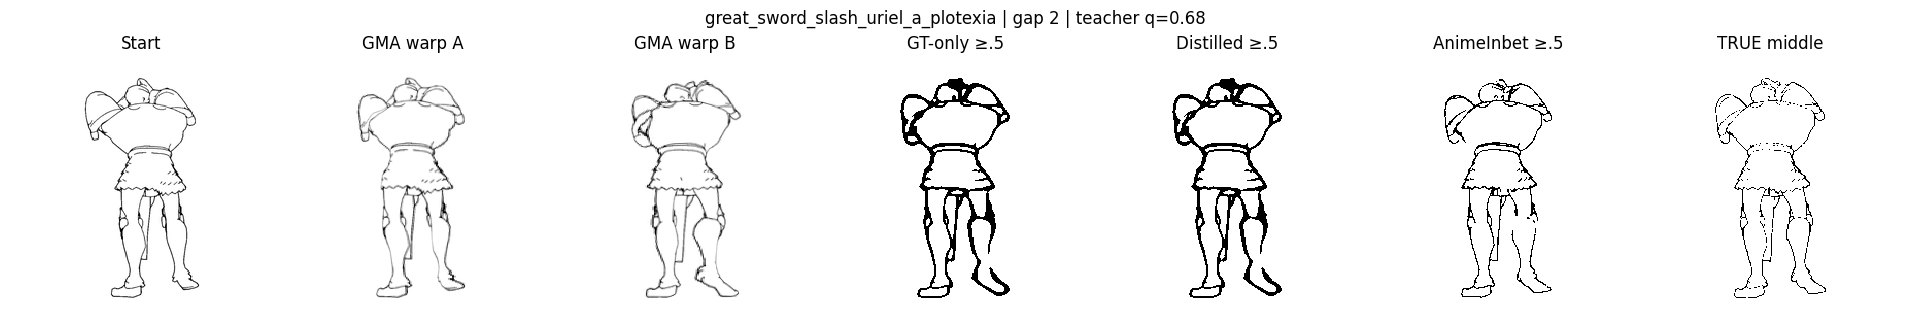

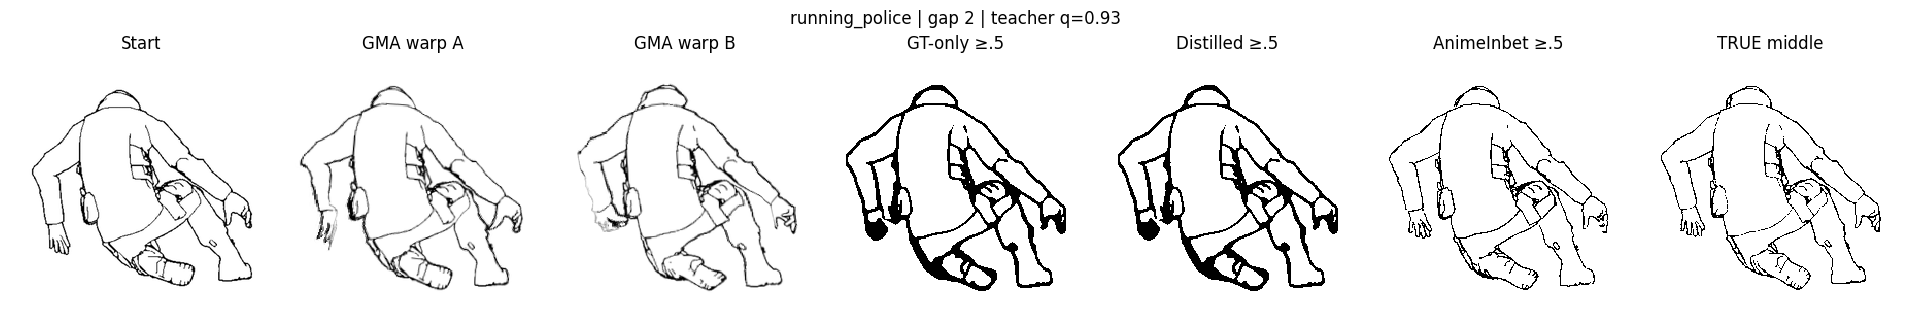

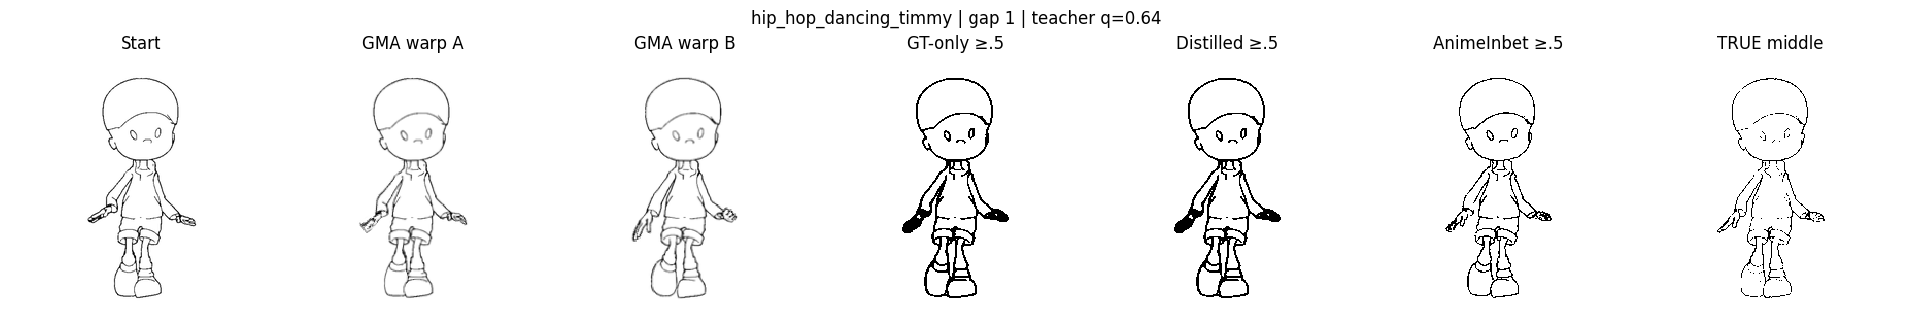

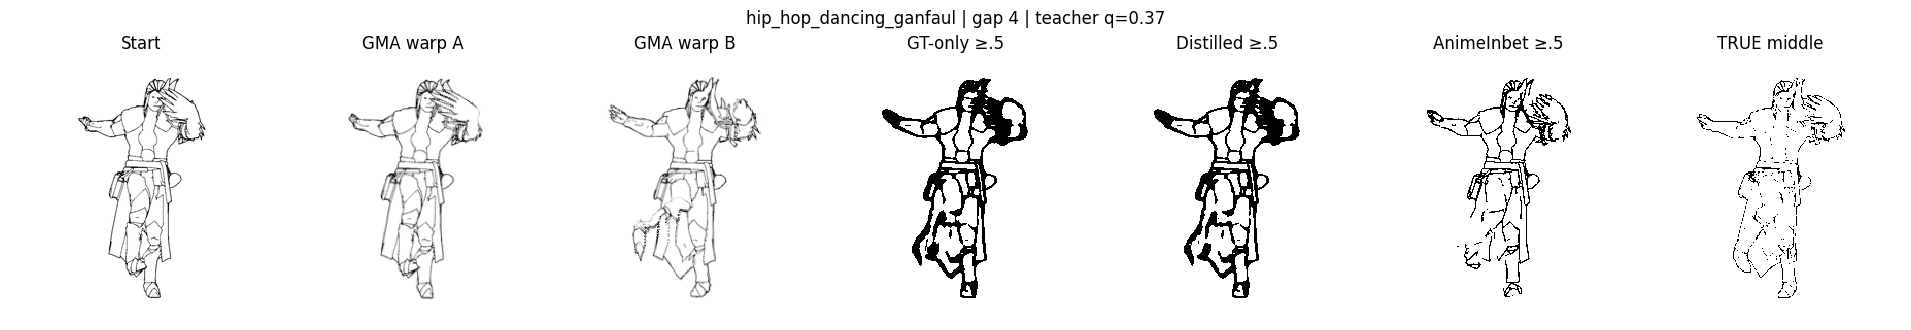

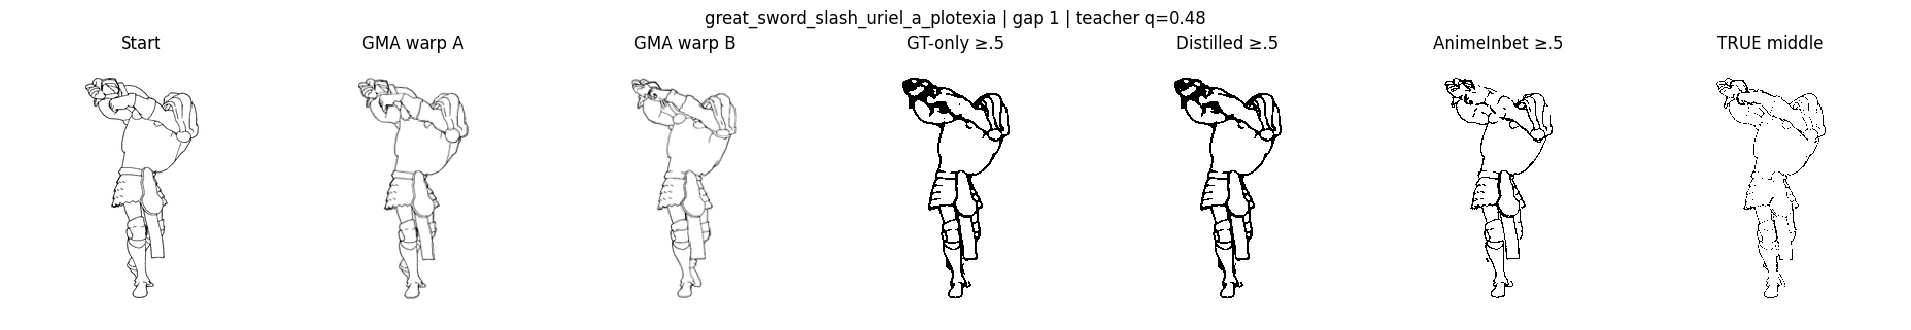

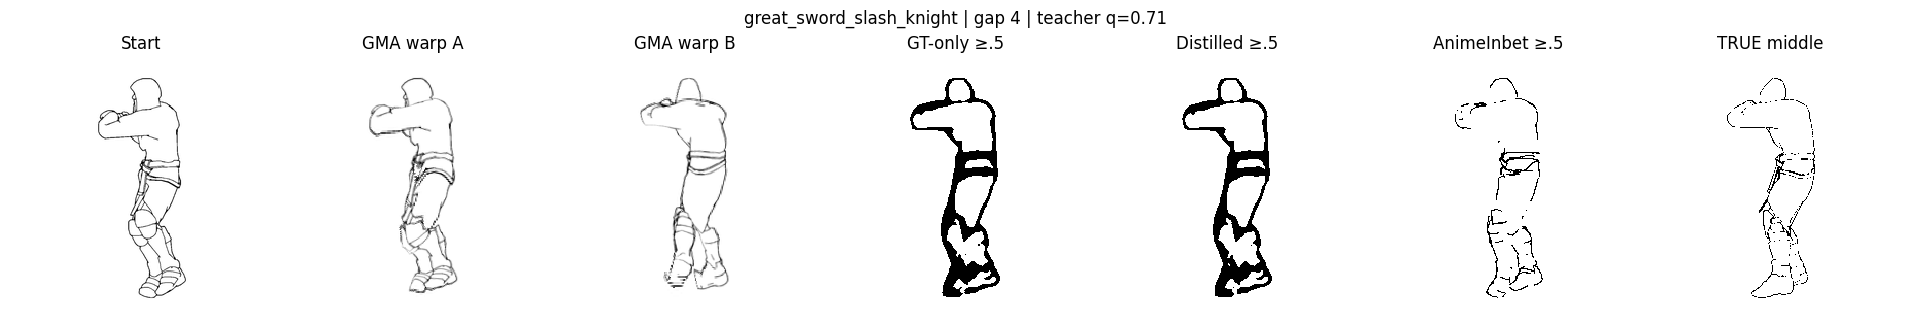

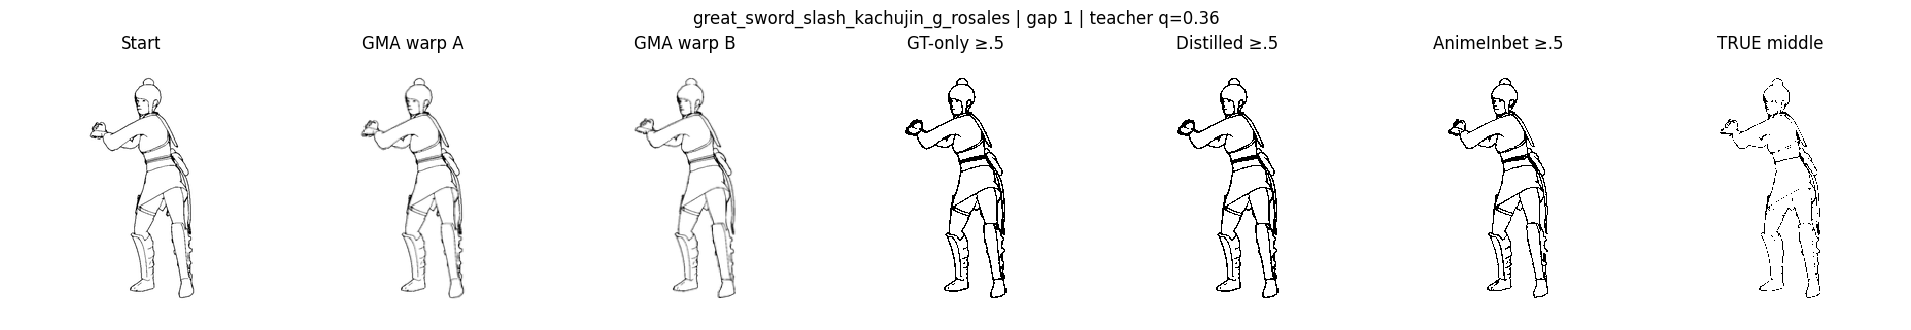

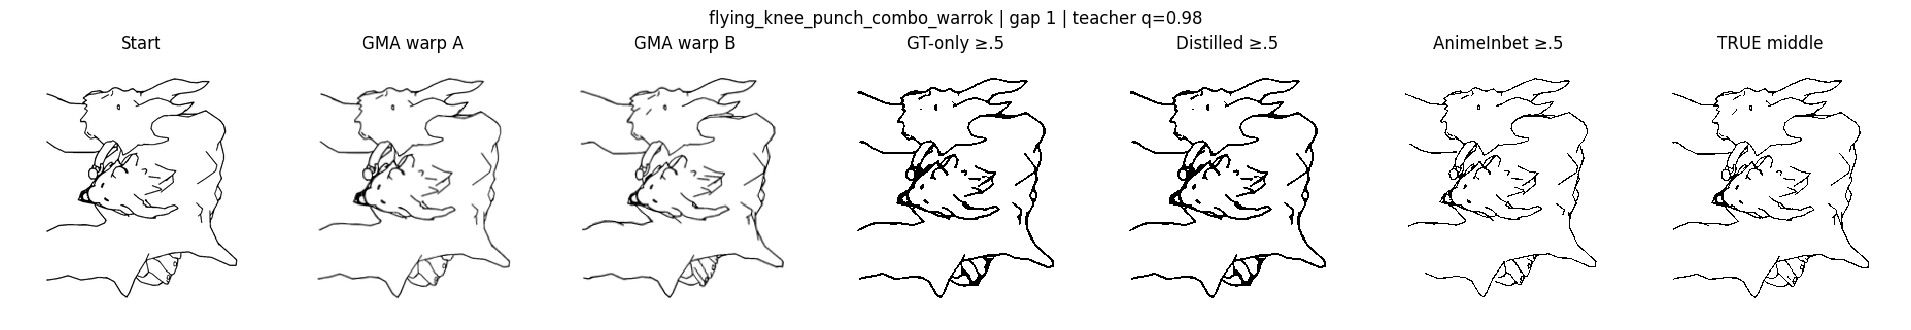

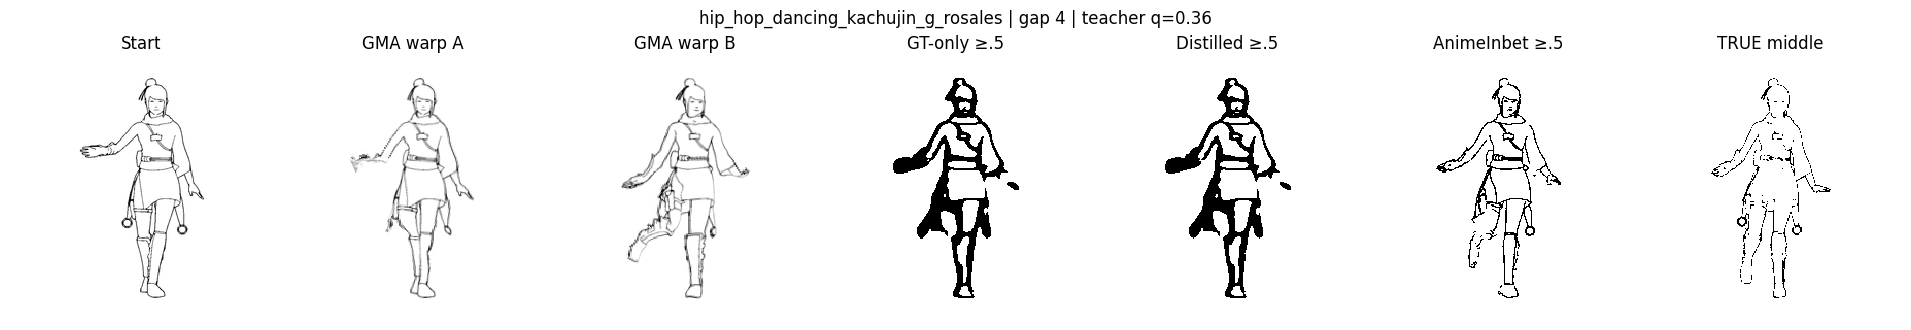

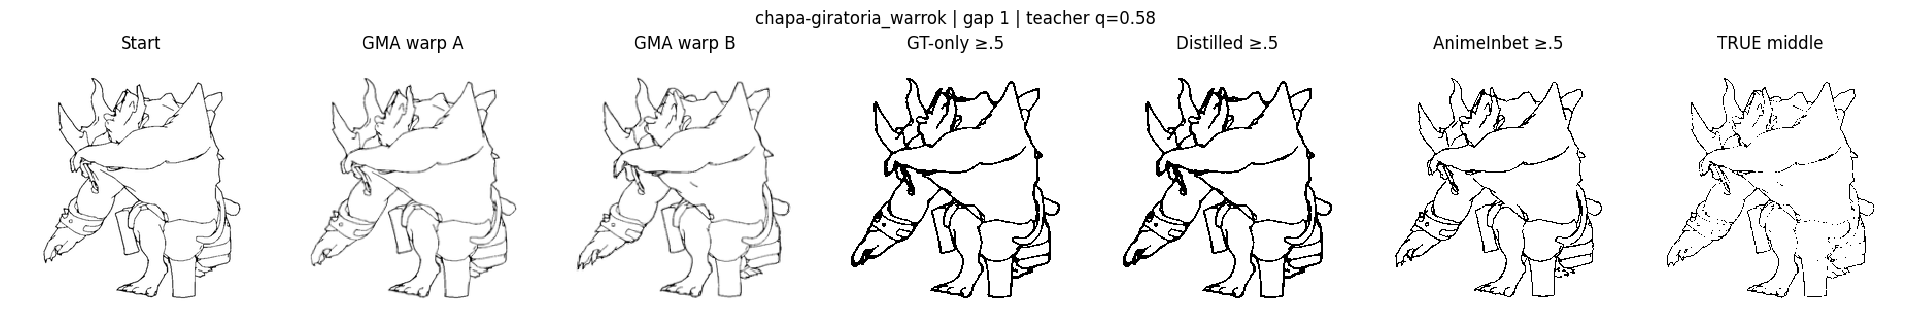

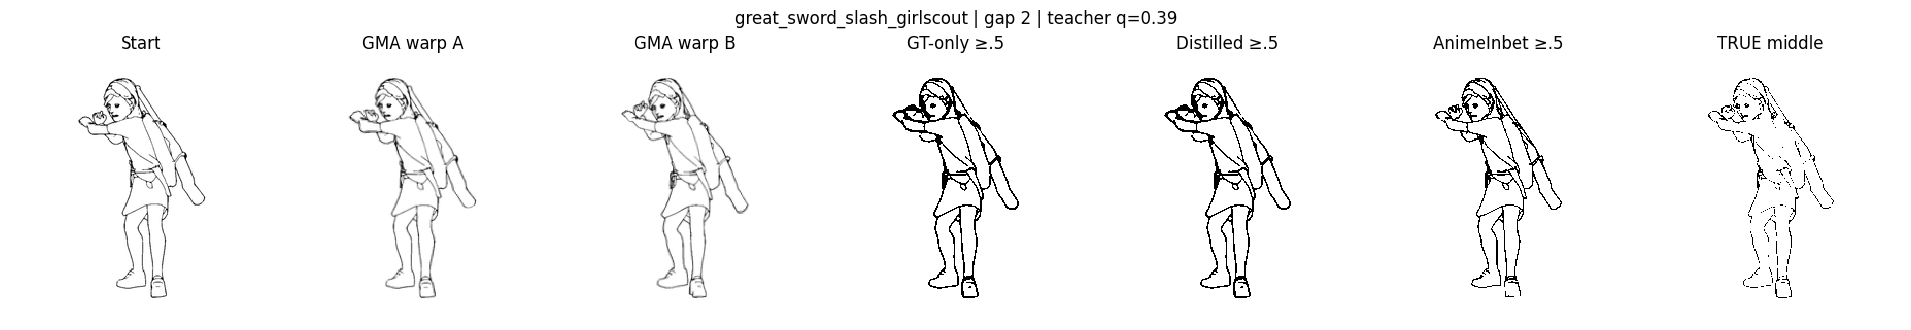

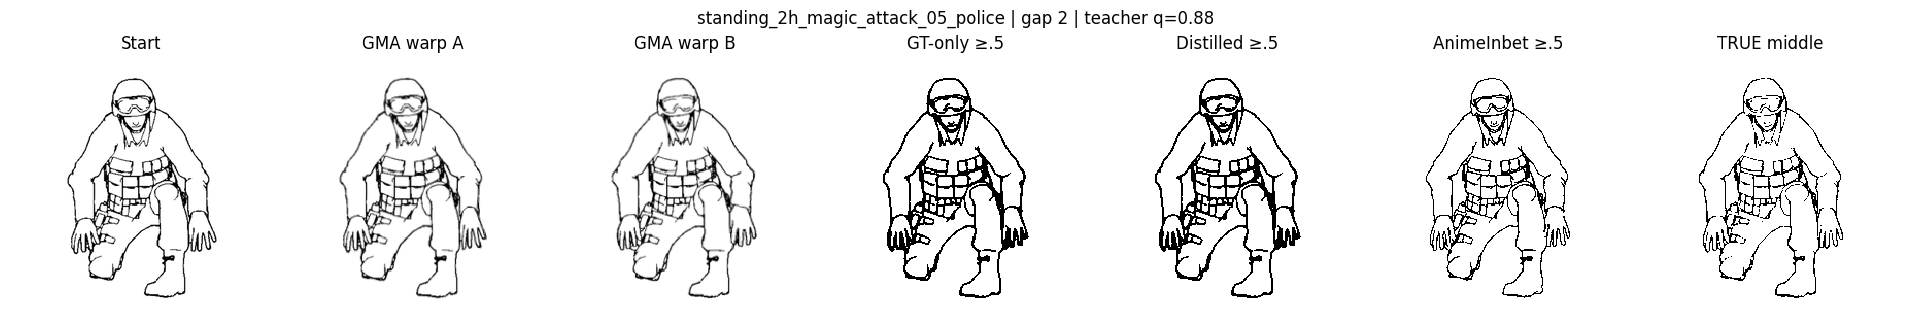

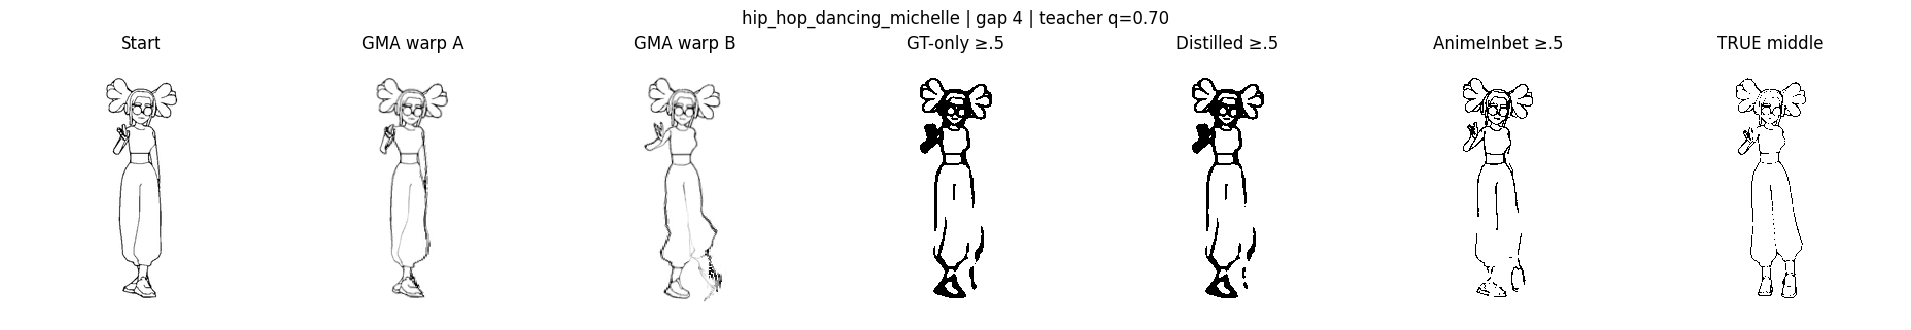

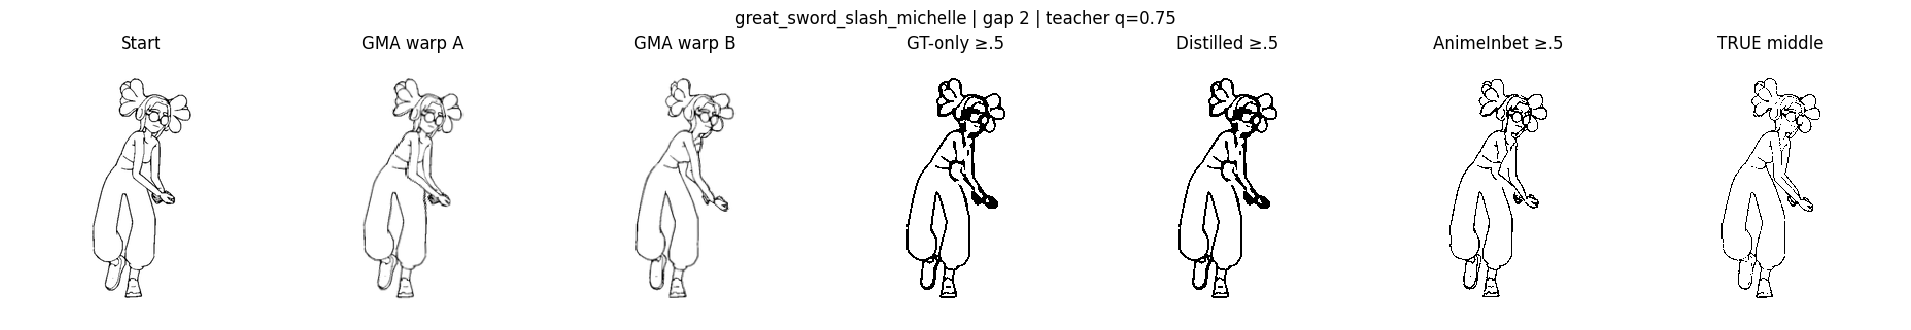

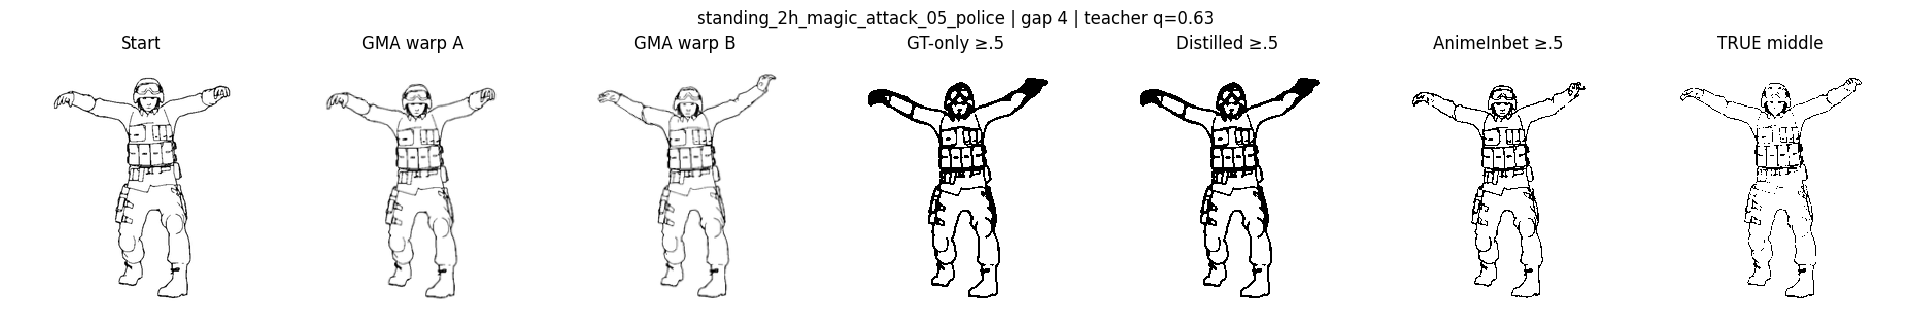

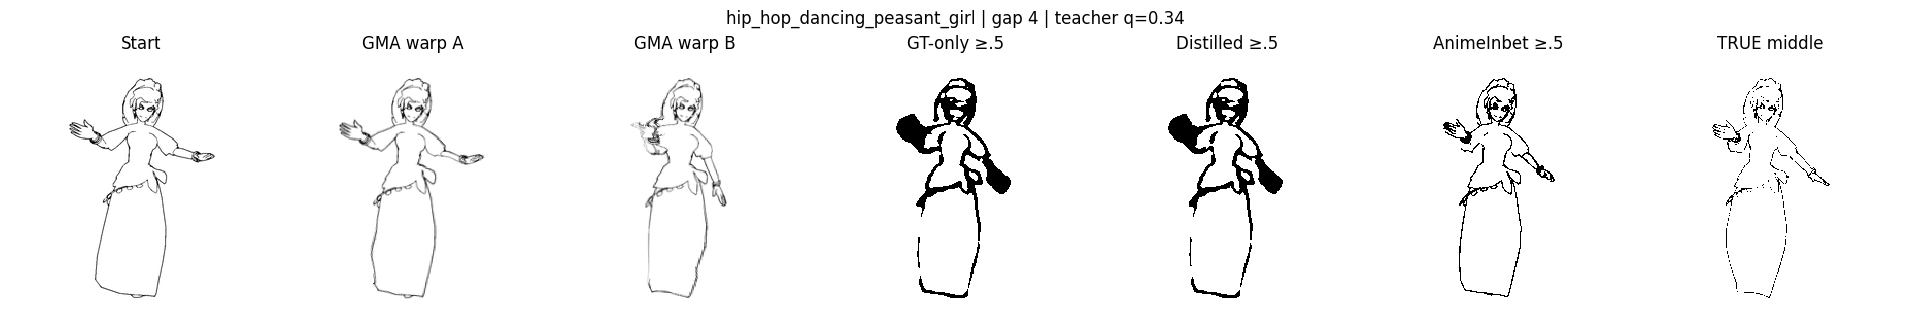

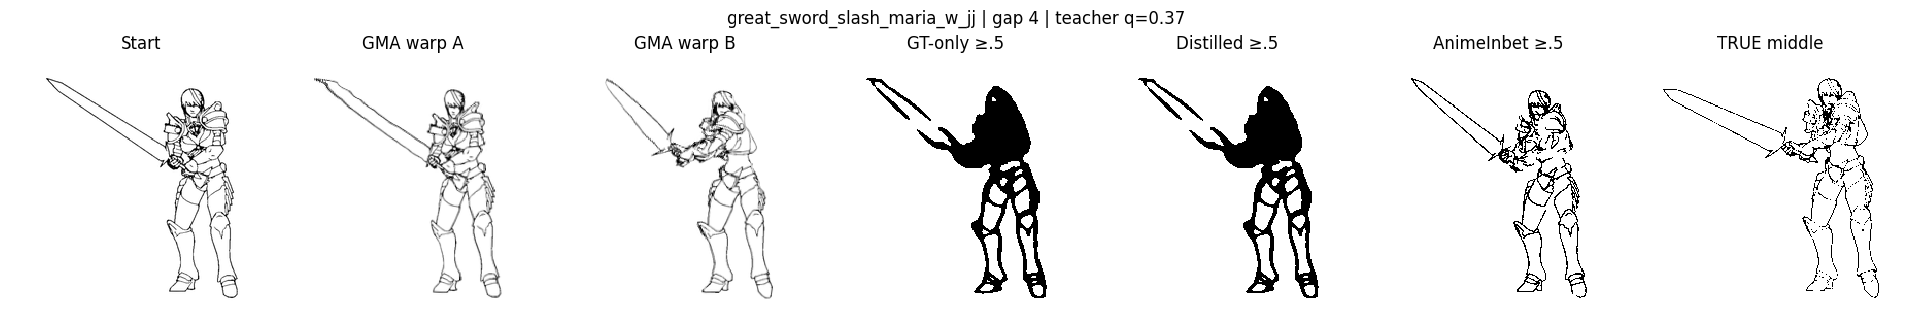

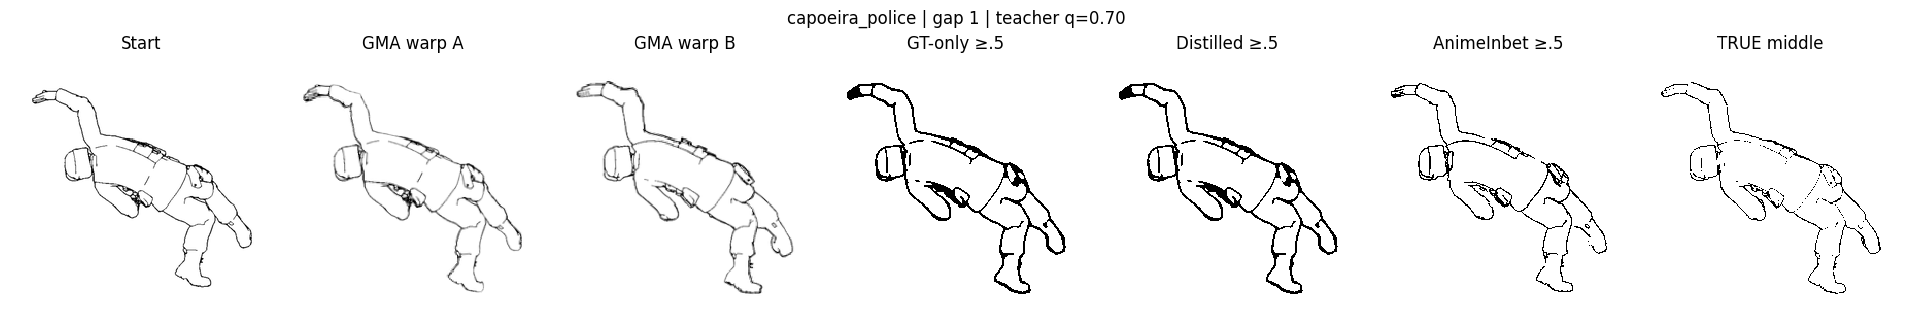

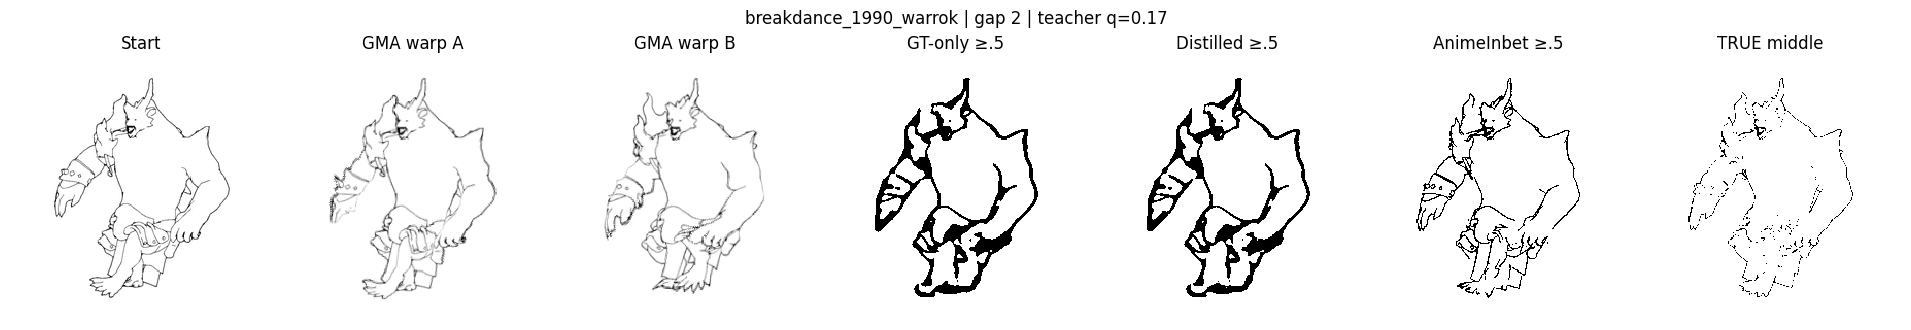

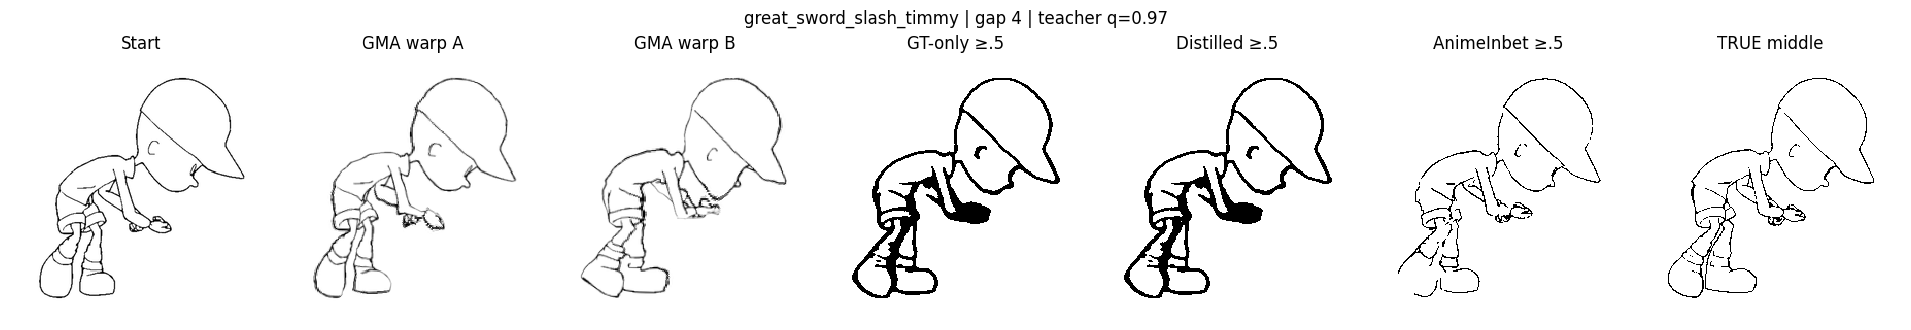

In [ ]:
models_to_score = {
    "control": OUT / "control/best.keras",
    "distilled": OUT / "distilled/best.keras",
}
comparison = [start_results]
networks = {}
for branch, path in models_to_score.items():
    m = keras.models.load_model(path, compile=False)
    networks[branch] = m
    df = evaluate_saved_model(m, val_rows, branch)
    comparison.append(df)

teacher_val_records = []
for r in val_rows:
    qrow = quality.loc[quality.id == r["id"]].iloc[0]
    teacher_val_records.append(
        dict(
            branch="AnimeInbet_graphs",
            id=r["id"],
            sequence=r["sequence"],
            gap=r["gap"],
            target_fraction=float((target_by_id(r["id"]) >= 0.5).mean()),
            line_f1=float(qrow.line_f1),
            chamfer_px=float(qrow.chamfer_px),
            mae=float(qrow.mae),
            ink_fraction=float(qrow.ink_fraction),
        )
    )
comparison.append(pd.DataFrame(teacher_val_records))
paired = pd.concat(comparison, ignore_index=True)
paired.to_csv(OUT / "matched_validation_per_pair.csv", index=False)
summary = pd.DataFrame(
    {label: sequence_score(g) for label, g in paired.groupby("branch")}
).T
summary = summary[["line_f1", "chamfer_px", "ink_ratio", "mae"]]
summary.to_csv(OUT / "matched_validation_summary.csv")
display(summary.round(5))

# Include the UNTOUCHED epoch-13 checkpoint when selecting the winner.
# A fine-tuned branch must improve F1 by at least 0.001, without materially
# worsening other metrics. These tolerances are heuristics, not significance tests.
MIN_F1_GAIN = 0.001
MAX_CHAMFER_REGRESSION = 0.02
MAX_MAE_REGRESSION = 0.001
MAX_INK_REGRESSION = 0.05
baseline = summary.loc["epoch13_GMA"]


def passes_baseline(candidate):
    return (
        candidate.line_f1 >= baseline.line_f1 + MIN_F1_GAIN
        and candidate.chamfer_px <= baseline.chamfer_px + MAX_CHAMFER_REGRESSION
        and candidate.mae <= baseline.mae + MAX_MAE_REGRESSION
        and abs(candidate.ink_ratio - 1.0)
        <= abs(baseline.ink_ratio - 1.0) + MAX_INK_REGRESSION
    )


eligible = ["epoch13_GMA"]
for branch in ("control", "distilled"):
    if passes_baseline(summary.loc[branch]):
        eligible.append(branch)
selected = max(
    eligible, key=lambda name: (summary.loc[name, "line_f1"], -summary.loc[name, "mae"])
)
kd_vs_control = dict(
    delta_f1=float(
        summary.loc["distilled", "line_f1"] - summary.loc["control", "line_f1"]
    ),
    delta_chamfer_px=float(
        summary.loc["distilled", "chamfer_px"] - summary.loc["control", "chamfer_px"]
    ),
    delta_mae=float(summary.loc["distilled", "mae"] - summary.loc["control", "mae"]),
)
atomic_json(
    OUT / "recommended_branch.json",
    dict(
        branch=selected,
        eligible=eligible,
        rule="F1 >= epoch13 + .001; Chamfer <= epoch13 + .02; MAE <= epoch13 + .001; ink-ratio error <= epoch13 + .05",
        kd_vs_control=kd_vs_control,
        matched_validation=summary.to_dict(orient="index"),
    ),
)
print(
    "Recommended:", selected, "| eligible:", eligible, "| KD vs control:", kd_vs_control
)

PANEL_DIR = OUT / "comparison_panels"
PANEL_DIR.mkdir(exist_ok=True)

PREVIEW_COUNT = 20

for r in random.Random(123).sample(val_rows, min(PREVIEW_COUNT, len(val_rows))):
    x, gt, teacher, _, _ = make_example(r)
    pred_control = tf.sigmoid(networks["control"](x[None], training=False))[
        0, ..., 0
    ].numpy()
    pred_kd = tf.sigmoid(networks["distilled"](x[None], training=False))[
        0, ..., 0
    ].numpy()
    displays = [
        x[..., 0],
        x[..., 2],
        x[..., 3],
        pred_control >= 0.5,
        pred_kd >= 0.5,
        teacher[..., 0] >= 0.5,
        gt[..., 0] >= 0.5,
    ]
    titles = [
        "Start",
        "GMA warp A",
        "GMA warp B",
        "GT-only ≥.5",
        "Distilled ≥.5",
        "AnimeInbet ≥.5",
        "TRUE middle",
    ]
    fig, axs = plt.subplots(
        1, len(displays), figsize=(19, 3.2), constrained_layout=True
    )
    for ax, image, title in zip(axs, displays, titles):
        ax.imshow(image, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"{r['sequence']} | gap {r['gap']} | teacher q={TRUST[r['id']]:.2f}")
    fig.savefig(PANEL_DIR / (r["id"] + ".png"), dpi=130)
    plt.show()
    plt.close(fig)

for m in networks.values():
    del m
del networks
gc.collect()
keras.backend.clear_session()

## Generate a middle drawing from two PNGs

Set `INFERENCE_A` and `INFERENCE_B` to uploaded files. Estimate their motion with GMA and run the selected U-Net using Stage 1 preprocessing. New-image inference needs only the endpoints, GMA, and the selected U-Net.

In [ ]:
from PIL import Image as PILImage


def two_png_inference(png_a, png_b, branch=None, dest=None):
    branch = branch or read_json(OUT / "recommended_branch.json")["branch"]
    assert branch in ("epoch13_GMA", "control", "distilled")
    # Fetch GMA resources ONLY if actual two-PNG inference is requested.
    from huggingface_hub import hf_hub_download

    if not (REPO_GMA / "core/network.py").is_file():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/zacjiang/GMA.git",
                str(REPO_GMA),
            ],
            check=True,
        )
    current_rev = subprocess.check_output(
        ["git", "-C", str(REPO_GMA), "rev-parse", "HEAD"], text=True
    ).strip()
    if current_rev != GMA_REV:
        subprocess.run(
            ["git", "-C", str(REPO_GMA), "fetch", "--depth", "1", "origin", GMA_REV],
            check=True,
        )
        subprocess.run(
            ["git", "-C", str(REPO_GMA), "checkout", "--detach", GMA_REV], check=True
        )
    assert (
        subprocess.check_output(
            ["git", "-C", str(REPO_GMA), "rev-parse", "HEAD"], text=True
        ).strip()
        == GMA_REV
    )
    ckpt = (
        Path(GMA_CKPT)
        if GMA_CKPT is not None
        else Path(
            hf_hub_download(
                repo_id="dreMaz/AnimeRun_ckpt", filename="20000_gma-animerun-v2-ft.pth"
            )
        )
    )
    assert ckpt.is_file() and sha256(ckpt) == GMA_SHA, (
        "GMA weights differ from cache provenance"
    )
    input_dir = OUT / "deployment_inputs"
    input_dir.mkdir(parents=True, exist_ok=True)
    a_path, b_path = input_dir / "0.png", input_dir / "1.png"
    for p_in, p_out in ((png_a, a_path), (png_b, b_path)):
        with PILImage.open(p_in) as img:
            processed = raster.prepare_image(img, size=SIZE)
        processed.save(p_out)
    inference_jobs = OUT / "inference_jobs.json"
    atomic_json(
        inference_jobs, [dict(id="user_two_pngs", split="infer", a="0.png", b="1.png")]
    )
    subdir = OUT / "deployment_flows"
    subprocess.run(
        [
            sys.executable,
            str(WORKER_PATH),
            str(REPO_GMA),
            str(ckpt),
            str(input_dir),
            str(subdir),
            str(inference_jobs),
            str(GMA_ITERS),
        ],
        check=True,
    )
    low = np.load(subdir / "infer/user_two_pngs.npy")
    a = raster.read_ink(a_path)
    b = raster.read_ink(b_path)
    x = raster.features_from_low(a, b, low)
    assert x.shape == (SIZE, SIZE, 8)
    model_path = BASE_PATH if branch == "epoch13_GMA" else OUT / branch / "best.keras"
    model = keras.models.load_model(model_path, compile=False)
    p = tf.sigmoid(tf.cast(model(x[None], training=False), tf.float32))[
        0, ..., 0
    ].numpy()
    dest = Path(dest) if dest else OUT / f"inference_middle_{branch}.png"
    raster.ink_image(p).save(dest)  # grayscale; unthresholded for antialiased ink
    raster.ink_image((p >= 0.5).astype(np.float32)).save(
        dest.with_name(dest.stem + "_cutoff_05.png")
    )
    print("Two PNGs + GMA + U-Net only:", dest)
    return dest


if INFERENCE_A is not None and INFERENCE_B is not None:
    output_png = two_png_inference(Path(INFERENCE_A), Path(INFERENCE_B))
    display(PILImage.open(output_png))
else:
    print(
        "Optional demo skipped. Set INFERENCE_A and INFERENCE_B to two uploaded PNG paths."
    )

Optional demo skipped. Set INFERENCE_A and INFERENCE_B to two uploaded PNG paths.


## Export models and results

Export epoch 13, both fine-tuned models, plots, and metrics. GMA and teacher caches are excluded. The following download helper splits the results ZIP into smaller parts.

In [ ]:
import zipfile

EXPORT = OUT / "08_distillation_models_results.zip"
baseline_export = OUT / "epoch13_GMA.keras"
if not baseline_export.is_file():
    shutil.copy2(BASE_PATH, baseline_export)
kept = [
    baseline_export,
    OUT / "experiment_config.json",
    OUT / "recommended_branch.json",
    OUT / "matched_validation_per_pair.csv",
    OUT / "matched_validation_summary.csv",
    OUT / "validation_epoch13_GMA.csv",
    OUT / "teacher_quality.csv",
    OUT / "gma_flow_worker08.py",
]
for branch in ("control", "distilled"):
    kept += [OUT / branch / name for name in ("best.keras", "last.keras", "state.json")]
    kept += list((OUT / branch).glob("validation_epoch*.csv"))
kept += list((OUT / "comparison_panels").glob("*.png"))
kept += list(OUT.glob("teacher_preview_*.png"))
assert all(p.is_file() for p in kept)
with zipfile.ZipFile(
    EXPORT, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=3
) as arc:
    for p in sorted(set(kept)):
        arc.write(p, arcname=str(p.relative_to(OUT)))
with zipfile.ZipFile(EXPORT) as arc:
    bad = arc.testzip()
    assert bad is None, f"Archive CRC failed: {bad}"
print(
    "Verified export:", EXPORT, "| size MiB:", round(EXPORT.stat().st_size / 1024**2, 1)
)
display(FileLink(str(EXPORT)))
print(
    "To resume the experiment, save the whole working output and attach it in a new Kaggle session."
)

Verified export: /kaggle/working/interframes_distillation08_inkfix/08_distillation_models_results.zip | size MiB: 37.8


/kaggle/working/interframes_distillation08_inkfix/08_distillation_models_results.zip

To resume the experiment, save the whole working output and attach it in a new Kaggle session.


In [ ]:
import os
import shutil
from pathlib import Path
from IPython.display import FileLink, display

src = OUT / "08_distillation_models_results.zip"
assert src.is_file(), f"ZIP not found: {src}"

os.chdir("/kaggle/working")

# Split large files into 95 MB parts
PART_SIZE = 95 * 1024 * 1024

if src.stat().st_size <= PART_SIZE:
    dst = Path("/kaggle/working") / src.name
    if src.resolve() != dst.resolve():
        shutil.copy2(src, dst)
    print("Download ZIP:")
    display(FileLink(dst.name))
else:
    print("ZIP is large. Download ALL parts:")

    with open(src, "rb") as f:
        i = 1
        while True:
            data = f.read(PART_SIZE)
            if not data:
                break

            name = f"{src.name}.part{i:03d}"
            Path(name).write_bytes(data)
            display(FileLink(name))
            i += 1

    print(f"Created {i - 1} parts.")

Download ZIP:


/kaggle/working/08_distillation_models_results.zip

## Interpret the pilot

Judge teacher assistance against the ground-truth-only run, as well as the original checkpoint. Inspect thin lines, overlaps, missing segments, and excess ink. A result on this small sample needs a broader comparison before it can support a general claim.

Source projects: [AnimeInbet](https://github.com/lisiyao21/AnimeInbet) and [GMA](https://github.com/zacjiang/GMA).